# Homework Assignment 1: Correlation Coefficient
**Course:** Basic Data Analysis (Prof. B. Mirkin) — Lecture 2: 2D Regression and Correlation Coefficient
**Dataset:** Spotify tracks (pop genre subset, 1000 tracks)

The notebook follows the 7 tasks of the assignment (slide 44) and uses the formulas from the lecture:

| Quantity | Formula (lecture slides) |
|---|---|
| Slope | $a = \rho \, \dfrac{\sigma(y)}{\sigma(x)}$ |
| Intercept | $b = \bar y - a\,\bar x$ |
| Residual variance | $L(a,b)/N = \sigma^2(y)\,(1-\rho^2)$ |
| Determinacy coefficient | $\rho^2$ |
| DA relative error | $\text{error}_1 = \dfrac{|y-\hat y|}{|y|}$ |
| ML relative error | $\text{error}_2 = \dfrac{|y-\hat y|}{|\hat y|}$ |

## Step 0. Prepare the dataset (split / subset)

The full file has 114,000 tracks across 114 genres (exactly 1000 tracks per genre). The professor's rule for large datasets is to *"select a smaller subset over a convenient feature"* (Lecture 1, slide 12), so I keep only the **pop** genre (1000 objects).

The course requirements for a dataset are: **≥ 80 objects, ≥ 5 features (≥ 3 quantitative), no missing values**. I check these below. (Note: a few tracks appear twice in the genre because they are listed on different albums; I keep all 1000 rows as given.)

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)

from pathlib import Path
DATA_PATH = Path.cwd() / "sparc_spotify" / "spotify_dataset.csv"
GENRES = ["pop"]                    # <- change here if you want other pop-family genres, e.g. ["pop", "k-pop", "j-pop"]

raw = pd.read_csv(DATA_PATH)
print("Full dataset:", raw.shape)

subset = raw[raw["track_genre"].isin(GENRES)].copy()
if len(subset) > 1000:                         # keep the set small (1000 objects)
    subset = subset.sample(1000, random_state=42)
subset = subset.reset_index(drop=True)
print("Subset      :", subset.shape)

Full dataset: (114000, 21)
Subset      : (1000, 21)


In [6]:
# Keep a meaningful set of features (more than 4, fewer than a dozen; 3+ quantitative)
features = ["track_name", "artists", "popularity", "duration_ms", "explicit",
            "danceability", "energy", "loudness", "valence", "tempo", "acousticness"]
df = subset[features].copy()

# ---- requirement checks ----
quant = df.select_dtypes("number").columns.tolist()
print("Objects            :", len(df), "(need >= 80)")
print("Features           :", df.shape[1], "(need >= 5)")
print("Quantitative       :", len(quant), "(need >= 3) ->", quant)
print("Missing values     :", int(df.isna().sum().sum()), "(need 0)")

df.to_csv("spotify_pop_1000.csv", index=False)   # save the small dataset
df.head()

Objects            : 1000 (need >= 80)
Features           : 11 (need >= 5)
Quantitative       : 8 (need >= 3) -> ['popularity', 'duration_ms', 'danceability', 'energy', 'loudness', 'valence', 'tempo', 'acousticness']
Missing values     : 0 (need 0)


,track_name,artists,popularity,duration_ms,explicit,danceability,energy,loudness,valence,tempo,acousticness
0,Blinding Lights,The Weeknd,91,200040,False,0.514,0.730,-5.934,0.334,171.005,0.00146
1,Mann Mera,Gajendra Verma,74,200120,False,0.535,0.765,-7.862,0.373,191.827,0.05400
2,Summer High,AP Dhillon,83,177391,False,0.860,0.541,-6.510,0.952,114.984,0.16500
3,Under The Influence,Chris Brown,96,184613,True,0.733,0.690,-5.529,0.310,116.992,0.06350
4,Starboy,The Weeknd;Daft Punk,90,230453,True,0.679,0.587,-7.015,0.486,186.003,0.14100


In [7]:
df[quant].describe().round(3)

,popularity,duration_ms,danceability,energy,loudness,valence,tempo,acousticness
count,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000,1000.000
mean,47.576,220672.776,0.630,0.606,-6.954,0.506,120.927,0.344
std,34.040,56548.741,0.137,0.178,2.563,0.212,31.066,0.286
min,0.000,62942.000,0.206,0.114,-20.647,0.038,55.832,0.000
25%,2.000,183066.000,0.541,0.488,-8.600,0.344,94.999,0.083
50%,66.000,211522.000,0.642,0.618,-6.724,0.498,118.660,0.281
75%,71.000,247175.500,0.727,0.727,-5.134,0.678,144.028,0.576
max,100.000,586075.000,0.918,0.986,-1.100,0.969,203.983,0.983


## Task 1. Find two features with a "linear-like" scatterplot

I look at the correlation matrix of the quantitative features and at the scatterplot matrix, then choose the pair with the clearest linear pattern.

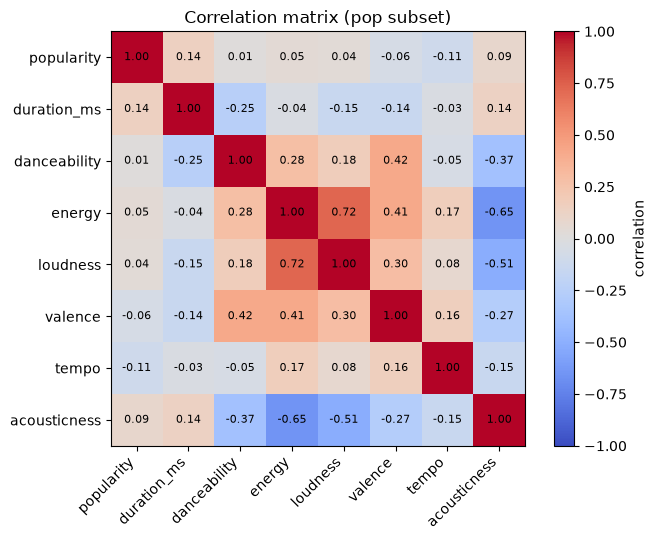

energy        loudness        0.723
              acousticness   -0.649
loudness      acousticness   -0.511
danceability  valence         0.416
energy        valence         0.414
dtype: float64


In [8]:
corr = df[quant].corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(quant))); ax.set_xticklabels(quant, rotation=45, ha="right")
ax.set_yticks(range(len(quant))); ax.set_yticklabels(quant)
for i in range(len(quant)):
    for j in range(len(quant)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="correlation")
ax.set_title("Correlation matrix (pop subset)")
plt.tight_layout(); plt.show()

# strongest pairs
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5).round(3))

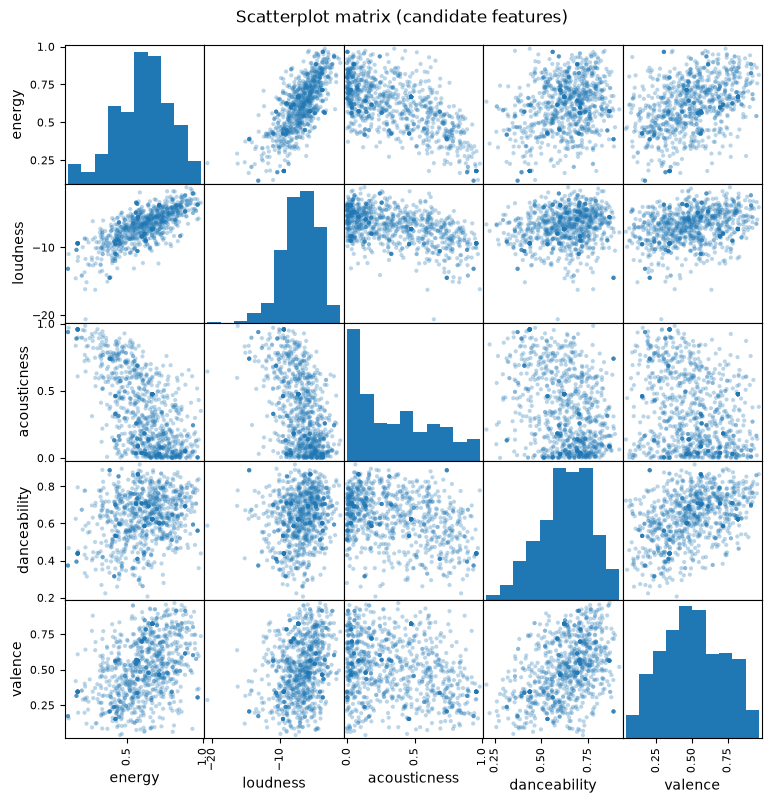

In [9]:
pd.plotting.scatter_matrix(df[["energy", "loudness", "acousticness", "danceability", "valence"]],
                           figsize=(9, 9), alpha=0.3, diagonal="hist")
plt.suptitle("Scatterplot matrix (candidate features)", y=0.92)
plt.show()

**Choice.** The strongest pair is **energy** and **loudness** (ρ ≈ 0.72). *Energy* (0–1) measures how intense and active a track feels, and loudness (in dB) is the average volume, so it is natural that louder tracks feel more energetic. The pair *energy – acousticness* is also strong (ρ ≈ −0.65), but its cloud is clearly curved, so energy–loudness is the better candidate for a linear model.

I take **x = energy** (predictor) and **y = loudness** (target).

## Task 2. Scatterplot and its suitability for linear regression

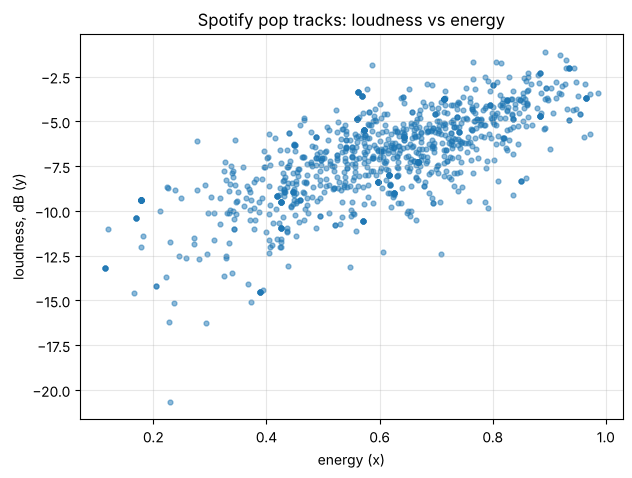

In [6]:
x = df["energy"].to_numpy()
y = df["loudness"].to_numpy()

plt.figure(figsize=(7, 5))
plt.scatter(x, y, s=12, alpha=0.5, color="tab:blue")
plt.xlabel("energy (x)"); plt.ylabel("loudness, dB (y)")
plt.title("Spotify pop tracks: loudness vs energy")
plt.grid(alpha=0.3); plt.show()

**Comment.** The cloud goes from the lower-left (quiet, low-energy tracks) to the upper-right (loud, high-energy tracks), so a *linear-like* trend is clearly visible and a straight line is a reasonable model. However:

- the cloud is **wide** — for the same energy, loudness can differ by several dB, so we should not expect very precise predictions;
- there are a few **quiet outliers** (5 tracks below −15 dB, all at low energy 0.2–0.4) that pull the left end of the cloud down, and loudness cannot exceed 0 dB, so the relation is not perfectly linear;
- the data are one homogeneous group (a single genre), so there is no risk of Simpson's paradox from mixing groups (slides 26–28).

Overall: **suitable for a linear regression, with moderate (not high) precision**.

## Task 3. Linear regression of loudness over energy

Using the lecture's closed-form solution (slide 15): $a=\rho\,\sigma(y)/\sigma(x)$, $b=\bar y-a\bar x$. I also check it against `numpy.polyfit` (the least-squares line).

In [7]:
rho = np.corrcoef(x, y)[0, 1]
a = rho * y.std() / x.std()          # slope
b = y.mean() - a * x.mean()          # intercept

# check against the numerical least squares solution
a_np, b_np = np.polyfit(x, y, 1)
print(f"Manual : loudness = {a:.4f} * energy + ({b:.4f})")
print(f"polyfit: loudness = {a_np:.4f} * energy + ({b_np:.4f})")

y_hat = a * x + b

Manual : loudness = 10.4257 * energy + (-13.2765)
polyfit: loudness = 10.4257 * energy + (-13.2765)


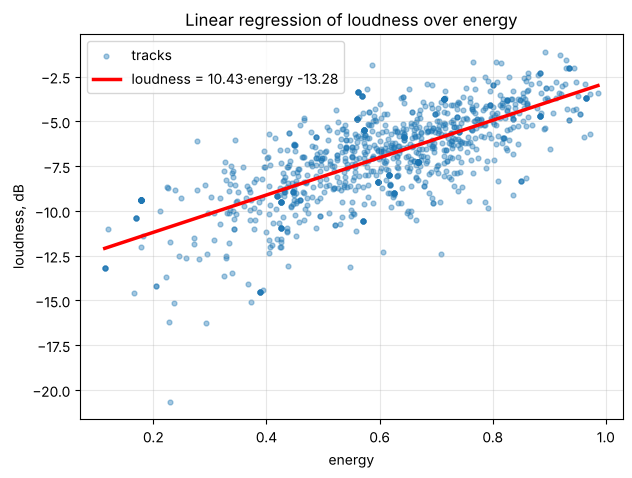

In [8]:
xs = np.linspace(x.min(), x.max(), 100)
plt.figure(figsize=(7, 5))
plt.scatter(x, y, s=12, alpha=0.4, label="tracks")
plt.plot(xs, a * xs + b, "r-", lw=2.5, label=f"loudness = {a:.2f}·energy {b:+.2f}")
plt.xlabel("energy"); plt.ylabel("loudness, dB")
plt.title("Linear regression of loudness over energy")
plt.legend(); plt.grid(alpha=0.3); plt.show()

**Meaning of the slope.** $a \approx 10.43$: when energy increases by **1 unit** (the whole 0→1 scale), the expected loudness increases by about **10.4 dB**. In practical terms, a track that is **0.1 more energetic** is expected to be about **1 dB louder**. The slope is positive, as expected from the scatterplot.

**Meaning of the intercept.** $b\approx -13.28$ dB is the expected loudness at energy = 0. This is an extrapolation (the lowest energy in the data is about 0.11), so it has no real practical meaning — as the lecture says, "this requires some fantasy".

## Task 4. Correlation and determinacy coefficients

In [9]:
det = rho ** 2
resid_var = np.mean((y - y_hat) ** 2)

print(f"Correlation coefficient rho   = {rho:.4f}")
print(f"Determinacy coefficient rho^2 = {det:.4f}  ({det*100:.1f}%)")
print()
print(f"Variance of y (loudness)      = {y.var():.4f}")
print(f"Residual variance (direct)    = {resid_var:.4f}")
print(f"sigma^2(y)*(1 - rho^2)        = {y.var() * (1 - det):.4f}   <- same, slide 15 formula (***)")

Correlation coefficient rho   = 0.7230
Determinacy coefficient rho^2 = 0.5228  (52.3%)

Variance of y (loudness)      = 6.5604
Residual variance (direct)    = 3.1308
sigma^2(y)*(1 - rho^2)        = 3.1308   <- same, slide 15 formula (***)


**Comment.** $\rho \approx 0.72$ shows a fairly strong positive linear association. The **determinacy coefficient** $\rho^2 \approx 0.52$ is the *proportion of the variance of loudness explained by the linear regression on energy*: about **52%** of the variability of loudness is accounted for by energy, and the remaining **≈ 48%** is residual variance (other factors: genre style, mastering, instrumentation, etc.). So the relation is real but far from deterministic.

## Task 5. Prediction for given values of the predictor

Following slide 17, I take four real tracks with different energy levels (low, medium, high), predict their loudness by the regression, and compare with the observed value.

In [10]:
rows = []
for q in [0.10, 0.40, 0.70, 0.95]:                # four energy levels (quantiles)
    i = int(np.argmin(np.abs(x - np.quantile(x, q))))
    rows.append(i)

pred = pd.DataFrame({
    "n": rows,
    "track": df.loc[rows, "track_name"].values,
    "x (energy)": x[rows],
    "y (loudness)": y[rows],
    "y* (predicted)": y_hat[rows],
})
pred["error1 DA, %"] = np.abs(pred["y (loudness)"] - pred["y* (predicted)"]) / np.abs(pred["y (loudness)"]) * 100
pred["error2 ML, %"] = np.abs(pred["y (loudness)"] - pred["y* (predicted)"]) / np.abs(pred["y* (predicted)"]) * 100
pred.round(3)

,n,track,x (energy),y (loudness),y* (predicted),"error1 DA, %","error2 ML, %"
0,764,Photograph,0.379,-10.480,-9.325,11.020,12.384
1,41,"Ranjha (From ""Shershaah"")",0.573,-5.843,-7.303,24.980,19.987
2,632,Ayyayo,0.705,-5.525,-5.926,7.265,6.773
3,436,If You Really Love Me (How Will I Know),0.883,-4.698,-4.071,13.354,15.413


In [11]:
# pure predictions for arbitrary energy values (no observed target needed)
for new_x in [0.2, 0.5, 0.75, 0.95]:
    print(f"energy = {new_x:.2f}  ->  predicted loudness = {a*new_x + b:6.2f} dB")

energy = 0.20  ->  predicted loudness = -11.19 dB
energy = 0.50  ->  predicted loudness =  -8.06 dB
energy = 0.75  ->  predicted loudness =  -5.46 dB
energy = 0.95  ->  predicted loudness =  -3.37 dB


**Comment.** The predictions are in the right range and follow the right order (higher energy → louder), but the errors of individual tracks are **noticeably large**: from about 7% to 25% (the exact values are in the table). A single track may be several dB away from the line, because the scatterplot is wide. This is the point of slides 17–21: a determinacy of ≈ 52% does **not** guarantee precise individual predictions. The regression is good for describing the *average* trend, less so for predicting one particular track.

## Task 6. Mean relative absolute error on all points: DA vs ML views

- **DA view** ("the observed value is true"): $\text{error}_1=|y-\hat y|/|y|$
- **ML view** ("the theoretical value is true, observation is noisy"): $\text{error}_2=|y-\hat y|/|\hat y|$

Because loudness is negative, absolute values are used in the denominators.

In [12]:
err_da = np.abs(y - y_hat) / np.abs(y)
err_ml = np.abs(y - y_hat) / np.abs(y_hat)

print(f"Min |y*| = {np.abs(y_hat).min():.2f} dB (far from 0, so ML error is well-defined)")
print()
print(f"Mean relative absolute error, DA view : {err_da.mean()*100:6.2f} %")
print(f"Mean relative absolute error, ML view : {err_ml.mean()*100:6.2f} %")
print(f"Median, DA / ML                       : {np.median(err_da)*100:.2f} % / {np.median(err_ml)*100:.2f} %")

Min |y*| = 3.00 dB (far from 0, so ML error is well-defined)

Mean relative absolute error, DA view :  23.13 %
Mean relative absolute error, ML view :  20.44 %
Median, DA / ML                       : 15.85 % / 16.19 %


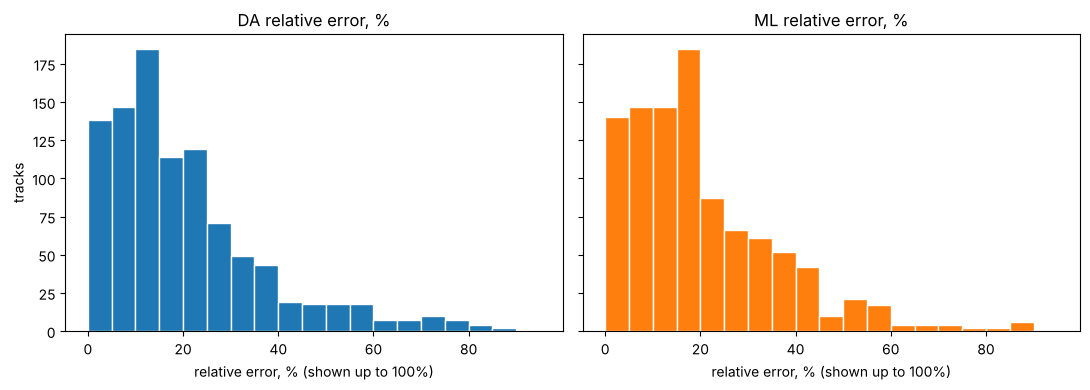

Tracks with DA error > 100%: 24 | with ML error > 100%: 1


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ax[0].hist(err_da * 100, bins=np.arange(0, 100, 5), color="tab:blue", edgecolor="white")
ax[0].set_title("DA relative error, %"); ax[0].set_ylabel("tracks")
ax[1].hist(err_ml * 100, bins=np.arange(0, 100, 5), color="tab:orange", edgecolor="white")
ax[1].set_title("ML relative error, %")
for k in (0, 1): ax[k].set_xlabel("relative error, % (shown up to 100%)")
plt.tight_layout(); plt.show()
print("Tracks with DA error > 100%:", int((err_da > 1).sum()), "| with ML error > 100%:", int((err_ml > 1).sum()))

**Comment.** The two views give different numbers: DA ≈ **23.1%** and ML ≈ **20.4%**. The only difference is the denominator. In the DA view it is the observed value $|y|$, in the ML view it is the fitted value $|\hat y|$. The regression line is a *smoothed* version of the data, so for tracks that are louder than predicted ($|y|<|\hat y|$) the DA error is larger than the ML error, and for tracks that are quieter than predicted it is the other way round. On average, DA is a bit larger here. The medians are almost equal (about 16% for both), so the gap is caused by a few extreme cases: the very loud tracks (|y| ≈ 1–2 dB) whose predicted loudness is much lower, where the DA denominator $|y|$ is tiny (24 tracks have a DA error above 100%, but only 1 has an ML error above 100%). As the lecture says, the two views "do differ" and one should always state which one is used.

## Task 7. Compare the errors and the determinacy coefficient

In [14]:
rmse = np.sqrt(resid_var)
print(f"Determinacy rho^2                     : {det*100:.1f} %")
print(f"Unexplained share 100 - rho^2         : {(1-det)*100:.1f} %  (share of VARIANCE)")
print(f"sqrt(1 - rho^2)                       : {np.sqrt(1-det)*100:.1f} %  (residual st.dev. relative to sigma(y))")
print(f"Residual st.dev. (RMSE)               : {rmse:.2f} dB   vs  sigma(y) = {y.std():.2f} dB")
print(f"RMSE relative to mean |y|             : {rmse/np.abs(y).mean()*100:.1f} %")
print(f"Mean relative error DA / ML           : {err_da.mean()*100:.1f} % / {err_ml.mean()*100:.1f} %")

Determinacy rho^2                     : 52.3 %
Unexplained share 100 - rho^2         : 47.7 %  (share of VARIANCE)
sqrt(1 - rho^2)                       : 69.1 %  (residual st.dev. relative to sigma(y))
Residual st.dev. (RMSE)               : 1.77 dB   vs  sigma(y) = 2.56 dB
RMSE relative to mean |y|             : 25.4 %
Mean relative error DA / ML           : 23.1 % / 20.4 %


**Comment.**

1. **What ρ² says:** ρ² ≈ **52%** of the variance of loudness is explained, so ≈ **48%** of the variance remains unexplained.
2. **What the errors say:** the mean relative errors are ≈ **23% (DA)** and ≈ **20% (ML)**. These two kinds of numbers are not directly comparable: 48% is a share of the **variance**, a *quadratic* quantity, while the relative errors are in the units of the data (slides 20–21).
3. **Square-root effect:** in the units of the data the typical error is $\sqrt{1-\rho^2}\approx 0.69$ of σ(y): the residual standard deviation is ≈ **1.77 dB** against σ(y) = 2.56 dB. So the regression shrinks the typical spread of loudness by only about **31%**, even though it "explains" 52% of the variance. Relative to the typical size of loudness (mean |y| ≈ 6.95 dB), 1.77 dB is ≈ 25%, which is consistent with the mean relative errors of 20–23%.
4. **Conclusion for precision:** a determinacy of 52% means a typical prediction is off by about ±1.8 dB, i.e. **20–25% of the value**. A higher ρ² would give smaller errors; but, as in the lecture's Iris example (ρ² = 92.7% and still 20–32% errors), **a high determinacy does not by itself warrant high precision**.
5. **DA vs ML:** 23.1% vs 20.4% — the difference comes from a few tracks with very small |y| (very loud), which inflate the DA error; the medians are nearly equal (≈ 16%). The two views would differ much more if y or ŷ were close to 0.

**Conclusion.** Energy is a meaningful linear predictor of loudness for pop tracks (ρ ≈ 0.72, ρ² ≈ 0.52; +0.1 energy ≈ +1 dB), but the linear model gives only rough individual predictions (≈ 20% mean relative error).